# 01. Exploración de Datos (EDA) — Nowcasting de Ventas Sectoriales (F104 - SRI)

**Proyecto:** PSet #3 — Experimentación y Selección del Modelo con MLflow  
**Fuentes en Snowflake:** `PSET2_DB.ANALYTICS.OBT_NOWCASTING_VENTAS` + `PSET2_DB.ANALYTICS.PRECIOS_RAMA_CNT46`  
**Propósito:** Auditar dimensiones, tipos, valores faltantes, distribución del objetivo, atípicos (IQR y Z-score), correlaciones (Pearson vs. Spearman) y documentar **4 hallazgos clave** que determinan el diseño de *features* y el modelado sin fuga de datos.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.datos import (
    COLUMNAS_FUGA,
    cargar_obt_completa,
    obtener_metadatos_snapshot,
    preparar_universo_nowcasting,
)
from src.pipeline import OBJETIVO, agregar_features

FIG_DIR = ROOT / "docs" / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (11, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})
sns.set_palette("deep")

df_full = cargar_obt_completa()
meta = obtener_metadatos_snapshot()
print("Metadatos del snapshot:", meta)
print("Dimensiones OBT completa (con INDICE_PRECIO_REAL):", df_full.shape)

Metadatos del snapshot: {'tabla_origen': 'PSET2_DB.ANALYTICS.OBT_NOWCASTING_VENTAS + PSET2_DB.ANALYTICS.PRECIOS_RAMA_CNT46', 'fecha_corte_snapshot': '2026-06-01', 'huella_datos': 'e4cd092d7514', 'git_commit': 'dda7927'}
Dimensiones OBT completa (con INDICE_PRECIO_REAL): (12635, 39)


## 1. Tamaño, tipos de datos, valores faltantes y estadística descriptiva

Se audita primero la tabla completa (`temprano_15d` y `definitivo`) para verificar la cobertura de cortes y el patrón estructural de nulos, y luego el universo de predicción (`TIPO_CORTE == 'temprano_15d'`), que representa la información observada en el día 15 después del cierre mensual.

In [2]:
print("Conteo de filas por TIPO_CORTE:")
resumen_corte = df_full.groupby("TIPO_CORTE").agg(
    filas=("VENTA_KEY", "count"),
    ramas=("CODIGO_INDUSTRIA", "nunique"),
    meses=("TIEMPO_KEY", "nunique"),
    fecha_min=("FECHA_MES", "min"),
    fecha_max=("FECHA_MES", "max"),
)
display(resumen_corte)

print("\nTipos de datos y valores faltantes en OBT completa:")
perfil_cols = pd.DataFrame({
    "dtype": df_full.dtypes.astype(str),
    "nulos_total": df_full.isna().sum(),
    "pct_nulos_total": (df_full.isna().mean() * 100).round(2),
    "nulos_temprano": df_full[df_full["TIPO_CORTE"] == "temprano_15d"].isna().sum(),
})
display(perfil_cols)

Conteo de filas por TIPO_CORTE:


,filas,ramas,meses,fecha_min,fecha_max
TIPO_CORTE,,,,,
definitivo,6348,46,138,2015-01-01,2026-06-01
temprano_15d,6287,46,138,2015-01-01,2026-06-01



Tipos de datos y valores faltantes en OBT completa:


,dtype,nulos_total,pct_nulos_total,nulos_temprano
VENTA_KEY,object,0,0.00,0
CODIGO_INDUSTRIA,object,0,0.00,0
TIEMPO_KEY,int32,0,0.00,0
CORTE_KEY,int8,0,0.00,0
NUMERO_RAMA,int8,0,0.00,0
NOMBRE_INDUSTRIA,object,0,0.00,0
SECTOR_MACRO,object,0,0.00,0
SECTOR_ECONOMICO,object,0,0.00,0
FECHA_MES,datetime64[ns],0,0.00,0
ANIO,int16,0,0.00,0


In [3]:
# Universo de modelado al corte temprano (día 15) + variable objetivo deflactada con precios reales
df_univ = preparar_universo_nowcasting(df_full)
df_feat = agregar_features(df_univ)
print("Universo temprano_15d sin fuga:", df_feat.shape)

cols_desc = [
    OBJETIVO,
    "ventas_temprano_ipc_real",
    "VENTAS_NOMINALES_USD",
    "NUM_DECLARANTES",
    "ventas_temprano_por_declarante_real",
    "INDICE_PRECIO_REAL",
    "INDICE_IPC_SIM",
    "RATIO_REPRESENTATIVIDAD_HIST_12M",
    "proyeccion_cobertura_12m",
]
print("\nEstadística descriptiva (millones de USD reales en ventas y target):")
display(df_feat[cols_desc].describe().round(2).T)

Universo temprano_15d sin fuga: (6287, 48)

Estadística descriptiva (millones de USD reales en ventas y target):


,count,mean,std,min,25%,50%,75%,max
ventas_reales_definitivo_ipc_real,6287.0,3.669600e+02,9.713800e+02,0.00,91.23,163.04,3.017400e+02,1.235965e+04
ventas_temprano_ipc_real,6287.0,1.308900e+02,3.425600e+02,0.00,18.85,44.58,1.054700e+02,4.095650e+03
VENTAS_NOMINALES_USD,6287.0,1.379364e+08,3.590304e+08,0.00,19139040.34,44960100.71,1.072843e+08,4.121160e+09
NUM_DECLARANTES,6287.0,1.416259e+04,3.392645e+04,1.00,577.00,2295.00,1.339700e+04,2.660380e+05
ventas_temprano_por_declarante_real,6287.0,9.946500e+02,6.301780e+03,0.00,3.52,14.76,5.398000e+01,1.175381e+05
INDICE_PRECIO_REAL,6287.0,1.037400e+02,1.968000e+01,23.83,98.34,100.47,1.050400e+02,3.553000e+02
INDICE_IPC_SIM,6287.0,1.063000e+02,7.640000e+00,93.73,99.64,106.11,1.128100e+02,1.199200e+02
RATIO_REPRESENTATIVIDAD_HIST_12M,6238.0,3.100000e-01,1.500000e-01,0.00,0.24,0.29,3.400000e-01,9.800000e-01
proyeccion_cobertura_12m,6238.0,3.685000e+02,9.718000e+02,0.00,90.77,162.15,3.026700e+02,1.238477e+04


## 2. Distribución del target y efecto de transformación logarítmica

El objetivo `ventas_reales_definitivo_ipc_real` mide las ventas definitivas mensuales de cada rama CIIU en **millones de USD reales** (deflactadas con el índice real `INDICE_PRECIO_REAL`, base 100). Dado que coexisten ramas pequeñas (p. ej. silvicultura o servicios culturales) con sectores masivos (comercio y extracción de petróleo), se evalúa la asimetría en escala original y bajo `log1p(y)`.

,valor
n,6287.000
media_musd,366.961
mediana_musd,163.036
std_musd,971.382
p05_musd,11.268
p95_musd,828.046
p99_musd,6243.311
max_musd,12359.647
asimetria_original,6.595
curtosis_original,47.404


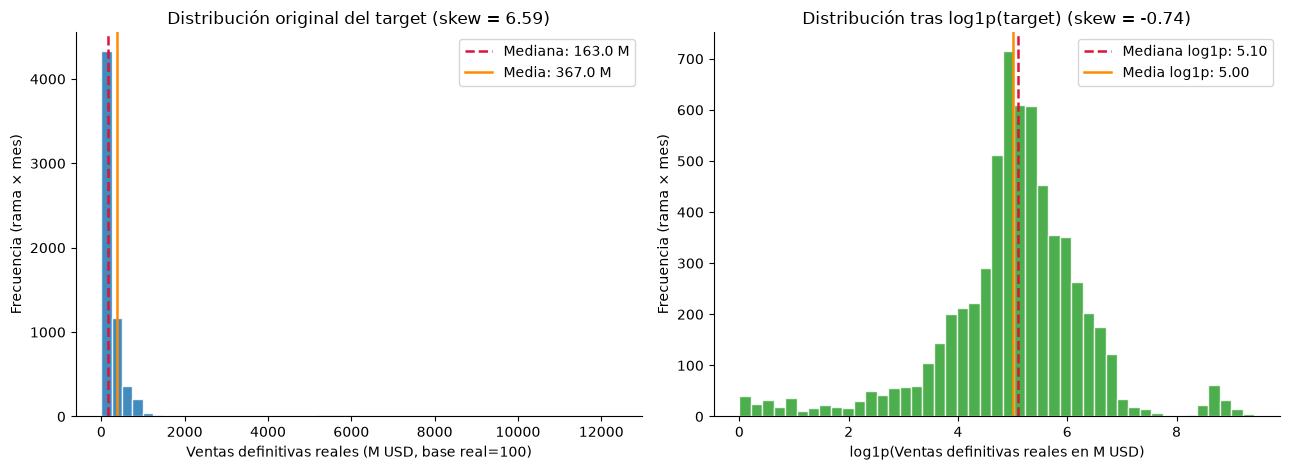

In [4]:
y = df_feat[OBJETIVO]
y_log = np.log1p(y)

stats_dist = pd.Series({
    "n": len(y),
    "media_musd": y.mean(),
    "mediana_musd": y.median(),
    "std_musd": y.std(),
    "p05_musd": y.quantile(0.05),
    "p95_musd": y.quantile(0.95),
    "p99_musd": y.quantile(0.99),
    "max_musd": y.max(),
    "asimetria_original": y.skew(),
    "curtosis_original": y.kurt(),
    "asimetria_log1p": y_log.skew(),
    "curtosis_log1p": y_log.kurt(),
})
display(stats_dist.round(3).to_frame("valor"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].hist(y, bins=50, color="#1f77b4", edgecolor="white", alpha=0.85)
axes[0].axvline(y.median(), color="crimson", linestyle="--", lw=1.8, label=f"Mediana: {y.median():.1f} M")
axes[0].axvline(y.mean(), color="darkorange", linestyle="-", lw=1.8, label=f"Media: {y.mean():.1f} M")
axes[0].set_title(f"Distribución original del target (skew = {y.skew():.2f})")
axes[0].set_xlabel("Ventas definitivas reales (M USD, base real=100)")
axes[0].set_ylabel("Frecuencia (rama × mes)")
axes[0].legend()

axes[1].hist(y_log, bins=45, color="#2ca02c", edgecolor="white", alpha=0.85)
axes[1].axvline(y_log.median(), color="crimson", linestyle="--", lw=1.8, label=f"Mediana log1p: {y_log.median():.2f}")
axes[1].axvline(y_log.mean(), color="darkorange", linestyle="-", lw=1.8, label=f"Media log1p: {y_log.mean():.2f}")
axes[1].set_title(f"Distribución tras log1p(target) (skew = {y_log.skew():.2f})")
axes[1].set_xlabel("log1p(Ventas definitivas reales en M USD)")
axes[1].set_ylabel("Frecuencia (rama × mes)")
axes[1].legend()

plt.tight_layout()
fig.savefig(FIG_DIR / "01_distribucion_target.png", dpi=180, bbox_inches="tight")
plt.show()

## 3. Detección de valores atípicos: IQR de Tukey y Z-score (`|Z| ≥ 3`)

Se aplican ambos métodos sobre el target y se auditan los casos marcados para separar **atípicos legítimos de dominio** (ramas macroeconómicas de gran escala y picos de diciembre) de **anomalías operativas** en la captura tributaria.

Q1 = 91.23 M USD | Q3 = 301.74 M USD | IQR = 210.51 M USD
Límite superior Tukey (Q3 + 1.5*IQR) = 617.51 M USD
Atípicos por IQR: 565 (8.99% del universo)
Atípicos por |Z| >= 3: 137 (2.18% del universo)

Ramas concentradoras de atípicos IQR (top 10):


,,,conteo,media_musd,max_musd
CODIGO_INDUSTRIA,NOMBRE_INDUSTRIA,SECTOR_MACRO,,,
035,Comercio al por mayor y al por menor; reparación de vehículos automotores y motocicletas,Comercio,138,6487.11,12359.65
041,"Actividades profesionales, científicas, técnicas y administrativas",Servicios empresariales y otros servicios,128,933.79,2427.63
024,Fabricación de productos refinados de petróleo y de otros,Manufactura,121,841.22,2015.06
036,Transporte y almacenamiento,Servicios empresariales y otros servicios,89,961.70,2134.97
007,Pesca y acuicultura,"Agricultura, ganaderia, silvicultura y pesca",25,690.97,846.91
034,Construcción,Construccion,23,861.80,1553.14
044,Actividades de atención de la salud humana y de asistencia social,Servicios sociales y administracion publica,13,808.83,1033.41
008,Extracción de petróleo crudo y gas natural y actividades de apoyo,Petroleo y minas,9,854.52,1265.84
038,Información y comunicación,Servicios empresariales y otros servicios,7,680.21,798.42



Anomalía operativa A — Meses con definitivo sin corte temprano_15d: 61 filas
  Ramas afectadas: {'020': 61} | Rango: 201701 - 202301
Anomalía operativa B — Filas en temprano_15d con ventas=0 y declarantes>0: 55 filas
  Observaciones con target = 0: 1


C:\Users\edwin\AppData\Local\Temp\ipykernel_32688\1452530207.py:43: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(y, vert=True, patch_artist=True, boxprops={"facecolor": "#aec7e8"})


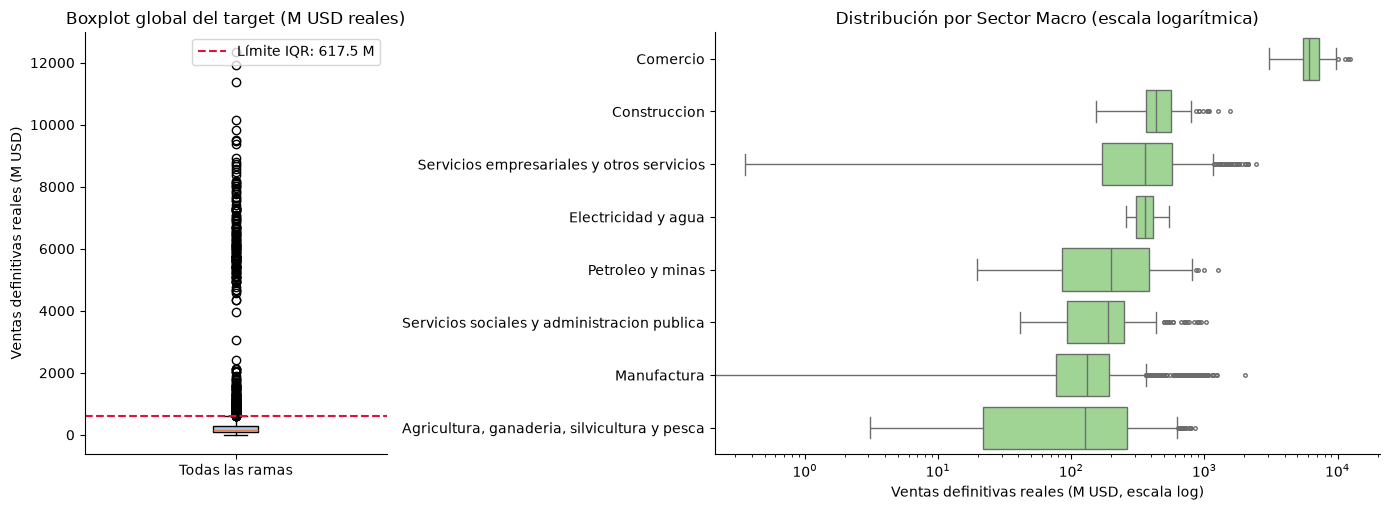

In [5]:
q1 = y.quantile(0.25)
q3 = y.quantile(0.75)
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

outliers_iqr = df_feat[(y < lim_inf) | (y > lim_sup)].copy()
z_scores = (y - y.mean()) / y.std(ddof=0)
outliers_z = df_feat[z_scores.abs() >= 3.0].copy()

print(f"Q1 = {q1:.2f} M USD | Q3 = {q3:.2f} M USD | IQR = {iqr:.2f} M USD")
print(f"Límite superior Tukey (Q3 + 1.5*IQR) = {lim_sup:.2f} M USD")
print(f"Atípicos por IQR: {len(outliers_iqr)} ({len(outliers_iqr)/len(df_feat)*100:.2f}% del universo)")
print(f"Atípicos por |Z| >= 3: {len(outliers_z)} ({len(outliers_z)/len(df_feat)*100:.2f}% del universo)")

print("\nRamas concentradoras de atípicos IQR (top 10):")
display(
    outliers_iqr.groupby(["CODIGO_INDUSTRIA", "NOMBRE_INDUSTRIA", "SECTOR_MACRO"])[OBJETIVO]
    .agg(conteo="count", media_musd="mean", max_musd="max")
    .sort_values("conteo", ascending=False)
    .head(10)
    .round(2)
)

# Anomalías operativas de la OBT (huecos en temprano_15d y ventas en cero con declarantes)
piv = df_full.pivot_table(
    index=["CODIGO_INDUSTRIA", "TIEMPO_KEY", "FECHA_MES"],
    columns="TIPO_CORTE",
    values="VENTAS_NOMINALES_USD",
    aggfunc="count",
    fill_value=0,
).reset_index()
solo_def = piv[(piv["temprano_15d"] == 0) & (piv["definitivo"] > 0)]
ceros_decl = df_feat[df_feat["FLAG_VENTAS_CERO_CON_DECLARANTES"] == 1]

print(f"\nAnomalía operativa A — Meses con definitivo sin corte temprano_15d: {len(solo_def)} filas")
print("  Ramas afectadas:", solo_def["CODIGO_INDUSTRIA"].value_counts().to_dict(),
      "| Rango:", solo_def["TIEMPO_KEY"].min(), "-", solo_def["TIEMPO_KEY"].max())
print(f"Anomalía operativa B — Filas en temprano_15d con ventas=0 y declarantes>0: {len(ceros_decl)} filas")
print("  Observaciones con target = 0:", int((df_feat[OBJETIVO] == 0).sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1, 2.2]})
axes[0].boxplot(y, vert=True, patch_artist=True, boxprops={"facecolor": "#aec7e8"})
axes[0].axhline(lim_sup, color="crimson", linestyle="--", label=f"Límite IQR: {lim_sup:.1f} M")
axes[0].set_title("Boxplot global del target (M USD reales)")
axes[0].set_ylabel("Ventas definitivas reales (M USD)")
axes[0].set_xticks([1])
axes[0].set_xticklabels(["Todas las ramas"])
axes[0].legend()

orden_sec = (
    df_feat.groupby("SECTOR_MACRO")[OBJETIVO].median().sort_values(ascending=False).index.tolist()
)
sns.boxplot(
    data=df_feat,
    y="SECTOR_MACRO",
    x=OBJETIVO,
    order=orden_sec,
    ax=axes[1],
    color="#98df8a",
    fliersize=2.5,
)
axes[1].set_xscale("log")
axes[1].set_title("Distribución por Sector Macro (escala logarítmica)")
axes[1].set_xlabel("Ventas definitivas reales (M USD, escala log)")
axes[1].set_ylabel("")

plt.tight_layout()
fig.savefig(FIG_DIR / "01_boxplots_atipicos.png", dpi=180, bbox_inches="tight")
plt.show()

## 4. Relación entre el target y los predictores: Pearson vs. Spearman

Se compara la correlación lineal (**Pearson**) frente a la monótona de rangos (**Spearman**). Se justifica priorizar **Spearman** para el diagnóstico exploratorio porque las 46 ramas abarcan múltiples órdenes de magnitud (colas pesadas) y las relaciones con la cobertura histórica o los declarantes presentan curvaturas y efectos multiplicativos; no obstante, las regresiones lineales evaluarán el impacto de mantener la escala original frente a la no linealidad de árboles.

,pearson,spearman,brecha_abs
proyeccion_cobertura_12m,0.9995,0.9930,0.0065
ventas_definitivo_real_lag12_musd,0.9919,0.9776,0.0143
ventas_temprano_ipc_real,0.9712,0.9489,0.0224
VENTAS_NOMINALES_USD,0.9423,0.9397,0.0026
ventas_definitivo_real_lag2_musd,0.9619,0.9385,0.0234
ventas_temprano_real_lag1_musd,0.9409,0.9054,0.0355
RATIO_REPRESENTATIVIDAD_HIST_12M,0.1200,0.4031,0.2831
NUM_DECLARANTES,0.8254,0.3375,0.4879
INDICE_IPC_SIM,0.0469,0.1045,0.0576
inflacion_sectorial_12m_lag1,-0.0159,0.0576,0.0734


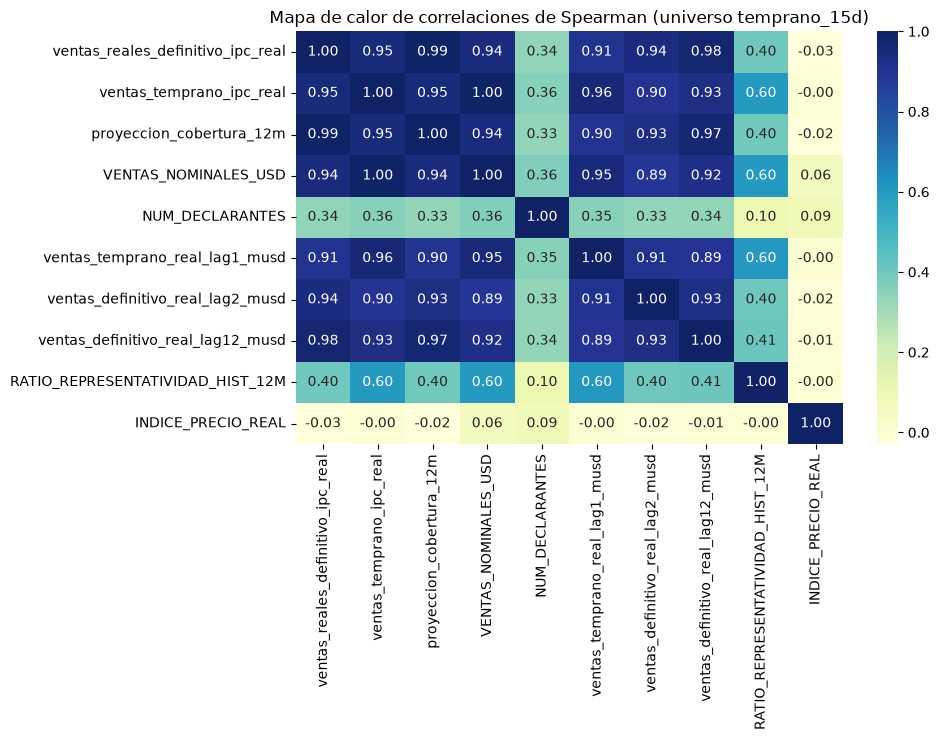

In [6]:
cols_corr = [
    OBJETIVO,
    "ventas_temprano_ipc_real",
    "proyeccion_cobertura_12m",
    "VENTAS_NOMINALES_USD",
    "NUM_DECLARANTES",
    "ventas_temprano_real_lag1_musd",
    "ventas_definitivo_real_lag2_musd",
    "ventas_definitivo_real_lag12_musd",
    "RATIO_REPRESENTATIVIDAD_HIST_12M",
    "INDICE_PRECIO_REAL",
    "INDICE_IPC_SIM",
    "inflacion_sectorial_12m_lag1",
    "impulso_declarantes",
]

pearson_target = df_feat[cols_corr].corr(method="pearson")[OBJETIVO]
spearman_target = df_feat[cols_corr].corr(method="spearman")[OBJETIVO]
comp_corr = pd.DataFrame({
    "pearson": pearson_target,
    "spearman": spearman_target,
    "brecha_abs": (spearman_target - pearson_target).abs(),
}).drop(index=OBJETIVO).sort_values("spearman", ascending=False)
display(comp_corr.round(4))

corr_mat = df_feat[cols_corr[:10]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 7.5))
sns.heatmap(corr_mat, annot=True, fmt=".2f", cmap="YlGnBu", center=0.5, ax=ax)
ax.set_title("Mapa de calor de correlaciones de Spearman (universo temprano_15d)")
plt.tight_layout()
fig.savefig(FIG_DIR / "01_correlacion_heatmap.png", dpi=180, bbox_inches="tight")
plt.show()

Correlación Pearson INDICE_PRECIO_REAL vs INDICE_IPC_SIM: 0.2875
Rango INDICE_PRECIO_REAL: [23.83, 355.30]
Rango INDICE_IPC_SIM:     [93.73, 119.92]


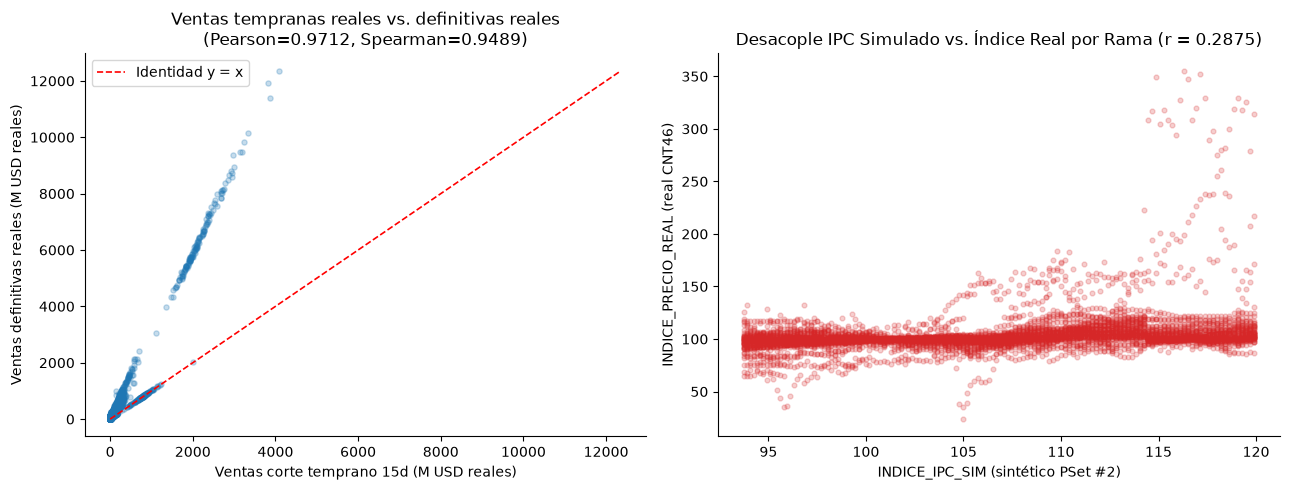

In [7]:
# Comparación visual: predictor principal vs target y desacople INDICE_IPC_SIM vs INDICE_PRECIO_REAL
corr_ipc = df_feat[["INDICE_PRECIO_REAL", "INDICE_IPC_SIM"]].corr().iloc[0, 1]
print(f"Correlación Pearson INDICE_PRECIO_REAL vs INDICE_IPC_SIM: {corr_ipc:.4f}")
print(f"Rango INDICE_PRECIO_REAL: [{df_feat['INDICE_PRECIO_REAL'].min():.2f}, {df_feat['INDICE_PRECIO_REAL'].max():.2f}]")
print(f"Rango INDICE_IPC_SIM:     [{df_feat['INDICE_IPC_SIM'].min():.2f}, {df_feat['INDICE_IPC_SIM'].max():.2f}]")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(
    df_feat["ventas_temprano_ipc_real"],
    df_feat[OBJETIVO],
    alpha=0.25,
    s=14,
    color="#1f77b4",
)
max_v = df_feat[OBJETIVO].max()
axes[0].plot([0, max_v], [0, max_v], "r--", lw=1.2, label="Identidad y = x")
axes[0].set_title(
    f"Ventas tempranas reales vs. definitivas reales\n(Pearson={comp_corr.loc['ventas_temprano_ipc_real','pearson']:.4f}, "
    f"Spearman={comp_corr.loc['ventas_temprano_ipc_real','spearman']:.4f})"
)
axes[0].set_xlabel("Ventas corte temprano 15d (M USD reales)")
axes[0].set_ylabel("Ventas definitivas reales (M USD reales)")
axes[0].legend()

axes[1].scatter(
    df_feat["INDICE_IPC_SIM"],
    df_feat["INDICE_PRECIO_REAL"],
    alpha=0.22,
    s=12,
    color="#d62728",
)
axes[1].set_title(f"Desacople IPC Simulado vs. Índice Real por Rama (r = {corr_ipc:.4f})")
axes[1].set_xlabel("INDICE_IPC_SIM (sintético PSet #2)")
axes[1].set_ylabel("INDICE_PRECIO_REAL (real CNT46)")

plt.tight_layout()
fig.savefig(FIG_DIR / "01_relacion_principal.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Verificación confirmatoria de los 4 hallazgos clave y consecuencias en el modelado

A continuación se ejecuta la comprobación cuantitativa de las columnas con fuga futura y del efecto estacional de diciembre, consolidando los 4 hallazgos exigidos.

In [8]:
# Evidencia de fuga si se mantuvieran columnas prohibidas y efecto estacional de diciembre
df_temprano_raw = df_full[df_full["TIPO_CORTE"] == "temprano_15d"].copy()
print("Columnas excluidas explícitamente por fuga:", COLUMNAS_FUGA)
corr_fuga = df_temprano_raw["RATIO_REPRESENTATIVIDAD_CORTE"].corr(
    df_temprano_raw["VENTAS_NOMINALES_DEFINITIVO_MES"]
)
print(f"Correlación RATIO_REPRESENTATIVIDAD_CORTE con target nominal: {corr_fuga:.4f} (fuga directa del mes t)")

estacional = df_feat.groupby("MES")[OBJETIVO].mean()
ratio_dic = estacional.loc[12] / estacional.drop(12).mean()
print(f"Promedio ventas reales en diciembre: {estacional.loc[12]:.2f} M vs resto de meses: {estacional.drop(12).mean():.2f} M (ratio={ratio_dic:.2f}x)")

hallazgos = pd.DataFrame([
    {
        "Hallazgo": "1. Cola derecha extrema y heterogeneidad sectorial",
        "Evidencia": f"Skewness={y.skew():.2f}, mediana={y.median():.1f} M vs P99={y.quantile(0.99):.1f} M; {len(outliers_iqr)} atípicos IQR legítimos y pico diciembre {ratio_dic:.2f}x.",
        "Consecuencia en el modelo": "Usar MAE como métrica técnica (robusta a colas) + WAPE macroeconómico; incorporar mes_sin/mes_cos/es_diciembre y modelos no lineales / árboles.",
    },
    {
        "Hallazgo": "2. Desacople entre IPC simulado e índice real por rama",
        "Evidencia": f"r={corr_ipc:.4f} entre INDICE_IPC_SIM [93.7, 119.9] e INDICE_PRECIO_REAL [23.8, 355.3].",
        "Consecuencia en el modelo": "Deflactar target y rezagos con INDICE_PRECIO_REAL (PRECIOS_RAMA_CNT46) y añadir inflación sectorial rezagada t-1.",
    },
    {
        "Hallazgo": "3. Fuga de información a posteriori en columnas de la OBT",
        "Evidencia": "RATIO_REPRESENTATIVIDAD_CORTE, RATIO_CORTE_VS_HIST_12M y FLAG_TEMPRANO_MAYOR_DEFINITIVO usan el definitivo del mismo mes t.",
        "Consecuencia en el modelo": "Exclusión estricta en src/datos.py; reemplazar por RATIO_REPRESENTATIVIDAD_HIST_12M (ventana [t-12, t-1]).",
    },
    {
        "Hallazgo": "4. Huecos estructurales en rama 020 y ceros con declarantes",
        "Evidencia": f"{len(solo_def)} meses sin temprano_15d en rama 020 (201701-202301) y {len(ceros_decl)} registros con ventas=0 y declarantes>0.",
        "Consecuencia en el modelo": "Calcular rezagos por INDICE_MES (no posicionales), iniciar train en 2016-01 (warmup 2015) e imputar con SimpleImputer dentro de Pipeline.",
    },
])
display(hallazgos)

Columnas excluidas explícitamente por fuga: ['RATIO_REPRESENTATIVIDAD_CORTE', 'RATIO_CORTE_VS_HIST_12M', 'VENTAS_NOMINALES_DEFINITIVO_MES', 'VENTAS_REALES_DEFINITIVO_MES', 'FLAG_TEMPRANO_MAYOR_DEFINITIVO']
Correlación RATIO_REPRESENTATIVIDAD_CORTE con target nominal: 0.1412 (fuga directa del mes t)
Promedio ventas reales en diciembre: 540.56 M vs resto de meses: 351.84 M (ratio=1.54x)


,Hallazgo,Evidencia,Consecuencia en el modelo
0,1. Cola derecha extrema y heterogeneidad secto...,"Skewness=6.59, mediana=163.0 M vs P99=6243.3 M...",Usar MAE como métrica técnica (robusta a colas...
1,2. Desacople entre IPC simulado e índice real ...,"r=0.2875 entre INDICE_IPC_SIM [93.7, 119.9] e ...",Deflactar target y rezagos con INDICE_PRECIO_R...
2,3. Fuga de información a posteriori en columna...,"RATIO_REPRESENTATIVIDAD_CORTE, RATIO_CORTE_VS_...",Exclusión estricta en src/datos.py; reemplazar...
3,4. Huecos estructurales en rama 020 y ceros co...,61 meses sin temprano_15d en rama 020 (201701-...,Calcular rezagos por INDICE_MES (no posicional...
